In [1]:
from sklearn.datasets import load_iris

iris = load_iris()
print("ML Classification Project Started!")
print("Total rows:", len(iris.target))

ML Classification Project Started!
Total rows: 150


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print("Dataset loaded:", X.shape)
display(X.head())

Dataset loaded: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    "Random Forest": RandomForestClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Random Forest trained successfully


In [5]:
results = []

for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro"),
        "Recall": recall_score(y_test, pred, average="macro"),
        "F1 Score": f1_score(y_test, pred, average="macro"),
        "ROC-AUC": roc_auc_score(
            y_test, prob, multi_class="ovr", average="macro"
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.933,0.933,0.933,0.933,0.997
1,Random Forest,0.900,0.902,0.900,0.900,0.987


In [6]:
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    print(name)
    print("5-fold CV accuracy:", round(scores.mean(), 3))

Logistic Regression
5-fold CV accuracy: 0.96
Random Forest
5-fold CV accuracy: 0.967


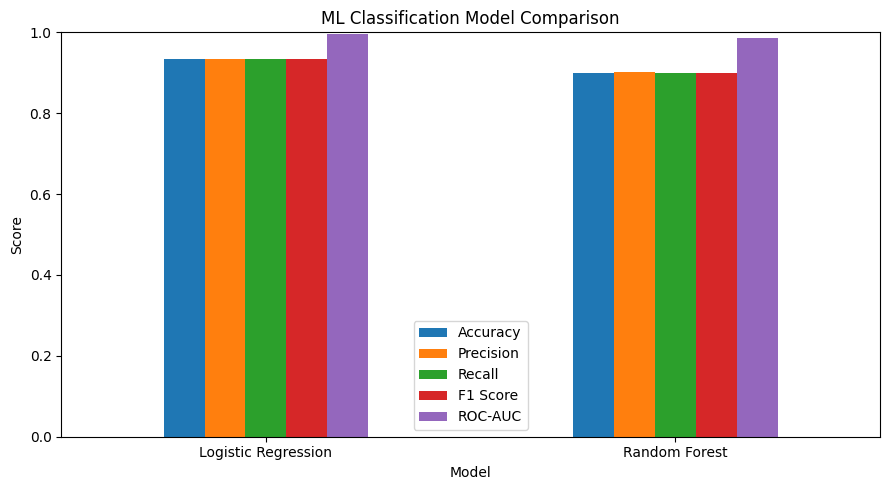

In [7]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", ylim=(0, 1), figsize=(9, 5))

plt.title("ML Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()